In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_excel(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Saving Online Retail.xlsx to Online Retail.xlsx
Dataset loaded successfully!
Shape: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [8]:
print(df.shape)
print(df.isnull().sum())
print(df.dtypes)

(541909, 8)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [9]:
# 1. Calculate missing-value percentages
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

print("Missing-value summary:")
print(missing_summary)

# 2. Count duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# 3. Investigate negative and zero quantities
print("\nNegative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())

# 4. Investigate prices
print("\nNegative prices:", (df["UnitPrice"] < 0).sum())
print("Zero prices:", (df["UnitPrice"] == 0).sum())

# 5. Check invoice identifiers
print("\nUnique invoices:", df["InvoiceNo"].nunique())
print("Unique product codes:", df["StockCode"].nunique())
print("Unique countries:", df["Country"].nunique())

Missing-value summary:
             Missing_Count  Missing_Percentage
InvoiceNo                0                0.00
StockCode                0                0.00
Description           1454                0.27
Quantity                 0                0.00
InvoiceDate              0                0.00
UnitPrice                0                0.00
CustomerID          135080               24.93
Country                  0                0.00

Exact duplicate rows: 5268

Negative quantities: 10624
Zero quantities: 0

Negative prices: 2
Zero prices: 2515

Unique invoices: 25900
Unique product codes: 4070
Unique countries: 38


In [10]:
# Inspect invoices whose invoice number starts with C
cancelled_mask = (
    df["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

cancelled_df = df[cancelled_mask]

print("Rows with invoice numbers starting with C:",
      len(cancelled_df))

print("\nExamples:")
print(cancelled_df.head(10))

print("\nQuantity summary:")
print(cancelled_df["Quantity"].describe())

Rows with invoice numbers starting with C: 9288

Examples:
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:

In [11]:
# Preserve the original dataset
df_raw = df.copy(deep=True)

# Create a separate working dataset
df_work = df_raw.copy()

print("Original rows:", len(df_raw))
print("Working rows:", len(df_work))

# Inspect some exact duplicate records
duplicate_rows = df_work[df_work.duplicated(keep=False)]

print("\nDuplicate records to investigate:")
print(duplicate_rows.head(10))

Original rows: 541909
Working rows: 541909

Duplicate records to investigate:
    InvoiceNo StockCode                        Description  Quantity  \
485    536409     22111       SCOTTIE DOG HOT WATER BOTTLE         1   
489    536409     22866      HAND WARMER SCOTTY DOG DESIGN         1   
494    536409     21866        UNION JACK FLAG LUGGAGE TAG         1   
517    536409     21866        UNION JACK FLAG LUGGAGE TAG         1   
521    536409     22900    SET 2 TEA TOWELS I LOVE LONDON          1   
527    536409     22866      HAND WARMER SCOTTY DOG DESIGN         1   
537    536409     22900    SET 2 TEA TOWELS I LOVE LONDON          1   
539    536409     22111       SCOTTIE DOG HOT WATER BOTTLE         1   
548    536412     22327  ROUND SNACK BOXES SET OF 4 SKULLS         1   
555    536412     22327  ROUND SNACK BOXES SET OF 4 SKULLS         1   

            InvoiceDate  UnitPrice  CustomerID         Country  
485 2010-12-01 11:45:00       4.95     17908.0  United Kingdom  

In [12]:
# Create a mask for cancellation invoice numbers
is_cancelled = (
    df_work["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

# Create a mask for negative quantities
is_negative_quantity = df_work["Quantity"] < 0

print("Cancellation rows:",
      is_cancelled.sum())

print("Negative quantity rows:",
      is_negative_quantity.sum())

print("Both cancellation and negative quantity:",
      (is_cancelled & is_negative_quantity).sum())

print("Negative quantities without C invoice:",
      (is_negative_quantity & ~is_cancelled).sum())

Cancellation rows: 9288
Negative quantity rows: 10624
Both cancellation and negative quantity: 9288
Negative quantities without C invoice: 1336


In [13]:
# Step 1: Remove exact duplicates from the working copy
df_clean = df_work.drop_duplicates().copy()

print("Rows after duplicate removal:", len(df_clean))

# Step 2: Identify cancellation invoice rows
is_cancelled = (
    df_clean["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

cancelled_df = df_clean.loc[is_cancelled].copy()

# Step 3: Keep non-cancellation rows separately
non_cancelled_df = df_clean.loc[~is_cancelled].copy()

# Step 4: Separate negative quantities
returns_df = non_cancelled_df.loc[
    non_cancelled_df["Quantity"] < 0
].copy()

# Step 5: Separate rows with zero or negative prices
invalid_price_df = non_cancelled_df.loc[
    non_cancelled_df["UnitPrice"] <= 0
].copy()

# Step 6: Create a positive-sales dataset
sales_df = non_cancelled_df.loc[
    (non_cancelled_df["Quantity"] > 0) &
    (non_cancelled_df["UnitPrice"] > 0)
].copy()

# Step 7: Fill missing product descriptions for reporting
sales_df["Description"] = (
    sales_df["Description"].fillna("Unknown product")
)

print("\n--- Dataset summary ---")
print("Original rows:", len(df_raw))
print("After duplicate removal:", len(df_clean))
print("Cancellation rows:", len(cancelled_df))
print("Negative-quantity rows outside C invoices:", len(returns_df))
print("Zero/negative-price rows outside C invoices:",
      len(invalid_price_df))
print("Positive-sales rows:", len(sales_df))

print("\nMissing values in sales dataset:")
print(sales_df.isnull().sum())

Rows after duplicate removal: 536641

--- Dataset summary ---
Original rows: 541909
After duplicate removal: 536641
Cancellation rows: 9251
Negative-quantity rows outside C invoices: 1336
Zero/negative-price rows outside C invoices: 2512
Positive-sales rows: 524878

Missing values in sales dataset:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64


In [14]:
# Calculate revenue for each product line
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

print(sales_df[
    ["InvoiceNo", "Description", "Quantity",
     "UnitPrice", "Revenue"]
].head(10))

# Calculate total sales revenue
total_revenue = sales_df["Revenue"].sum()

# Calculate total units sold
total_units = sales_df["Quantity"].sum()

# Count unique invoices
total_invoices = sales_df["InvoiceNo"].nunique()

print("\n--- Sales KPIs ---")
print(f"Total revenue: £{total_revenue:,.2f}")
print(f"Total units sold: {total_units:,}")
print(f"Unique invoices in sales data: {total_invoices:,}")

  InvoiceNo                          Description  Quantity  UnitPrice  Revenue
0    536365   WHITE HANGING HEART T-LIGHT HOLDER         6       2.55    15.30
1    536365                  WHITE METAL LANTERN         6       3.39    20.34
2    536365       CREAM CUPID HEARTS COAT HANGER         8       2.75    22.00
3    536365  KNITTED UNION FLAG HOT WATER BOTTLE         6       3.39    20.34
4    536365       RED WOOLLY HOTTIE WHITE HEART.         6       3.39    20.34
5    536365         SET 7 BABUSHKA NESTING BOXES         2       7.65    15.30
6    536365    GLASS STAR FROSTED T-LIGHT HOLDER         6       4.25    25.50
7    536366               HAND WARMER UNION JACK         6       1.85    11.10
8    536366            HAND WARMER RED POLKA DOT         6       1.85    11.10
9    536367        ASSORTED COLOUR BIRD ORNAMENT        32       1.69    54.08

--- Sales KPIs ---
Total revenue: £10,642,110.80
Total units sold: 5,572,420
Unique invoices in sales data: 19,960


In [15]:
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 products by revenue:")
print(product_revenue.head(10))

Top 10 products by revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


In [16]:
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(country_revenue.head(10))

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


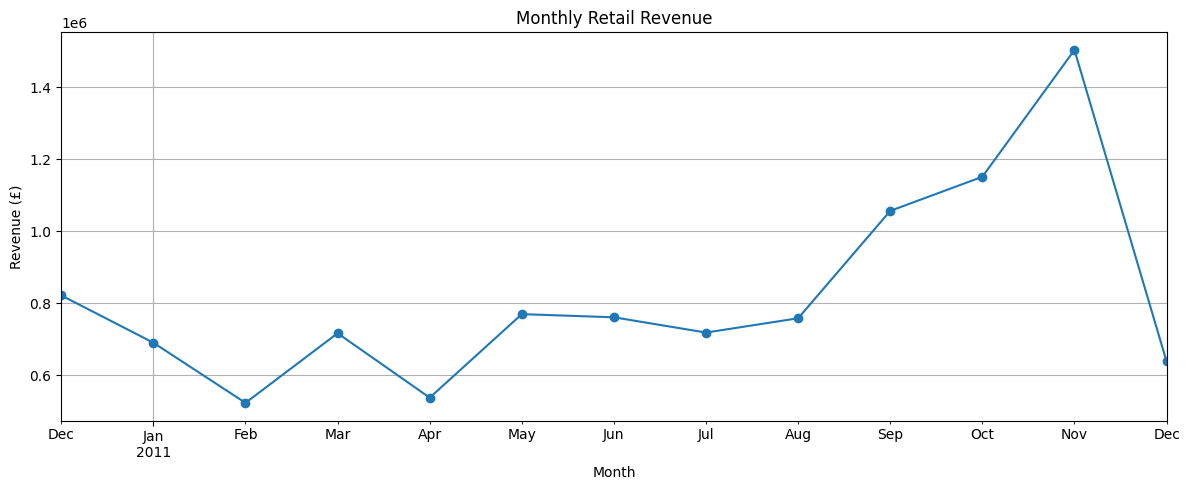

In [17]:
# Extract month from each invoice date
sales_df["Month"] = (
    sales_df["InvoiceDate"]
    .dt.to_period("M")
)

# Calculate monthly revenue
monthly_revenue = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
)

# Create a line chart
plt.figure(figsize=(12, 5))

monthly_revenue.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd
import numpy as np

# Work on a separate copy
customer_df = sales_df.copy()

# Keep rows with identifiable customers
customer_df = customer_df.dropna(
    subset=["CustomerID"]
).copy()

# Convert IDs to strings for identification
customer_df["CustomerID"] = (
    customer_df["CustomerID"].astype("int64").astype(str)
)

# Ensure invoice dates are datetime values
customer_df["InvoiceDate"] = pd.to_datetime(
    customer_df["InvoiceDate"]
)

print("Rows with known customers:", len(customer_df))
print("Unique customers:", customer_df["CustomerID"].nunique())
print("Missing customer IDs:", customer_df["CustomerID"].isnull().sum())

Rows with known customers: 392692
Unique customers: 4338
Missing customer IDs: 0


In [19]:
# Define the reference date
reference_date = (
    customer_df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

# Aggregate customer behaviour
rfm = customer_df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

# Calculate recency in days
rfm["Recency"] = (
    reference_date - rfm["LastPurchase"].dt.normalize()
).dt.days

# Arrange columns for readability
rfm = rfm[
    ["Recency", "Frequency", "Monetary", "LastPurchase"]
]

print(rfm.head(10))
print("\nRFM summary:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

            Recency  Frequency  Monetary        LastPurchase
CustomerID                                                  
12346           326          1  77183.60 2011-01-18 10:01:00
12347             3          7   4310.00 2011-12-07 15:52:00
12348            76          4   1797.24 2011-09-25 13:13:00
12349            19          1   1757.55 2011-11-21 09:51:00
12350           311          1    334.40 2011-02-02 16:01:00
12352            37          8   2506.04 2011-11-03 14:37:00
12353           205          1     89.00 2011-05-19 17:47:00
12354           233          1   1079.40 2011-04-21 13:11:00
12355           215          1    459.40 2011-05-09 13:49:00
12356            23          3   2811.43 2011-11-17 08:40:00

RFM summary:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     93.059474     4.272015    2048.688081
std     100.012264     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000 

In [20]:
print("Customers:", len(rfm))
print("Average recency:", round(rfm["Recency"].mean(), 2), "days")
print("Average invoice frequency:", round(rfm["Frequency"].mean(), 2))
print("Total positive sales revenue: £",
      round(rfm["Monetary"].sum(), 2))

print("\nTop 10 customers by monetary value:")
print(
    rfm.sort_values("Monetary", ascending=False)
       .head(10)
)

Customers: 4338
Average recency: 93.06 days
Average invoice frequency: 4.27
Total positive sales revenue: £ 8887208.89

Top 10 customers by monetary value:
            Recency  Frequency   Monetary        LastPurchase
CustomerID                                                   
14646             2         73  280206.02 2011-12-08 12:12:00
18102             1         60  259657.30 2011-12-09 11:50:00
17450             9         46  194390.79 2011-12-01 13:29:00
16446             1          2  168472.50 2011-12-09 09:15:00
14911             2        201  143711.17 2011-12-08 15:54:00
12415            25         21  124914.53 2011-11-15 14:22:00
14156            10         55  117210.08 2011-11-30 10:54:00
17511             3         31   91062.38 2011-12-07 10:12:00
16029            39         63   80850.84 2011-11-01 10:27:00
12346           326          1   77183.60 2011-01-18 10:01:00


In [21]:
# Recency: fewer days is better, so reverse the score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: more purchases is better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: more positive sales revenue is better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

print(rfm[
    ["Recency", "Frequency", "Monetary",
     "R_Score", "F_Score", "M_Score", "RFM_Score"]
].head(10))

            Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
CustomerID                                                                   
12346           326          1  77183.60        1        1        4       114
12347             3          7   4310.00        4        4        4       444
12348            76          4   1797.24        2        3        4       234
12349            19          1   1757.55        3        1        4       314
12350           311          1    334.40        1        1        2       112
12352            37          8   2506.04        3        4        4       344
12353           205          1     89.00        1        1        1       111
12354           233          1   1079.40        1        1        3       113
12355           215          1    459.40        1        1        2       112
12356            23          3   2811.43        3        3        4       334


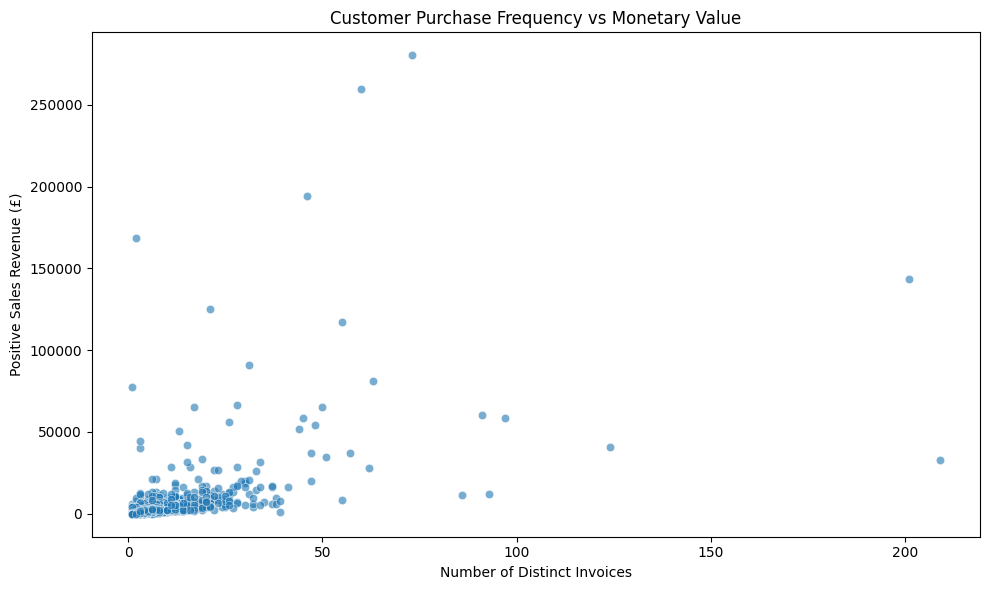

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    alpha=0.6
)

plt.title("Customer Purchase Frequency vs Monetary Value")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Positive Sales Revenue (£)")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Select the three RFM features
features = ["Recency", "Frequency", "Monetary"]

# Create a separate modelling dataset
X = rfm[features].copy()

# Check the data before transformation
print("Missing values:")
print(X.isnull().sum())

print("\nMinimum values:")
print(X.min())

print("\nMaximum values:")
print(X.max())

print("\nFeature distributions:")
print(X.describe())

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Minimum values:
Recency      1.00
Frequency    1.00
Monetary     3.75
dtype: float64

Maximum values:
Recency         374.00
Frequency       209.00
Monetary     280206.02
dtype: float64

Feature distributions:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     93.059474     4.272015    2048.688081
std     100.012264     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.750000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [24]:
# RFM values should be non-negative for log1p
assert (X >= 0).all().all(), "Investigate negative RFM values first."

# Reduce the effect of highly skewed values
X_log = np.log1p(X)

# Put all three features on comparable scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)
print("Scaled feature means:",
      X_scaled.mean(axis=0).round(3))
print("Scaled feature standard deviations:",
      X_scaled.std(axis=0).round(3))

Original shape: (4338, 3)
Scaled shape: (4338, 3)
Scaled feature means: [ 0. -0. -0.]
Scaled feature standard deviations: [1. 1. 1.]


In [25]:
# Test between 2 and 7 clusters
k_values = range(2, 8)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(10000, len(X_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette": silhouette_scores
})

print(results.round(4))

   K    Inertia  Silhouette
0  2  6476.5069      0.4325
1  3  4858.2441      0.3363
2  4  3925.4256      0.3329
3  5  3269.2747      0.3181
4  6  2841.4171      0.3129
5  7  2532.9847      0.3103


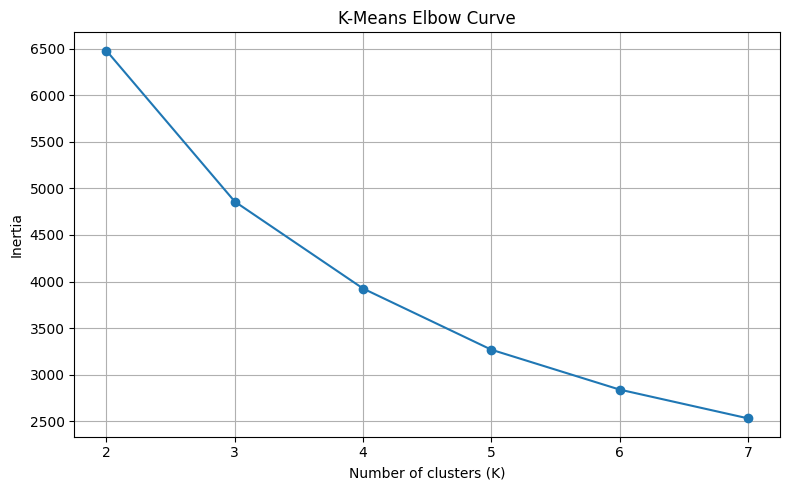

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(results["K"], results["Inertia"], marker="o")
plt.title("K-Means Elbow Curve")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

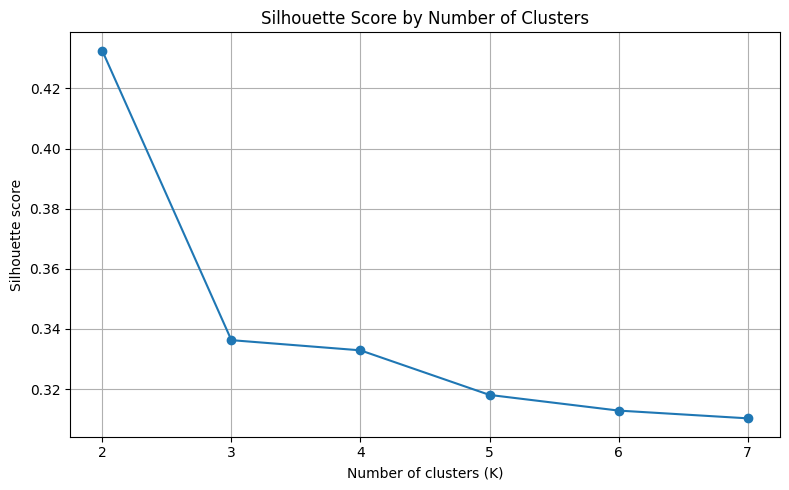

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(
    results["K"],
    results["Silhouette"],
    marker="o"
)
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
X.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [29]:
from sklearn.cluster import KMeans

# Train the baseline model
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Create a separate customer table with cluster labels
rfm_clustered = rfm.copy()
rfm_clustered["Cluster"] = kmeans_2.fit_predict(X_scaled)

print(rfm_clustered.head())
print("\nNumber of customers in each cluster:")
print(rfm_clustered["Cluster"].value_counts().sort_index())

            Recency  Frequency  Monetary        LastPurchase  R_Score  \
CustomerID                                                              
12346           326          1  77183.60 2011-01-18 10:01:00        1   
12347             3          7   4310.00 2011-12-07 15:52:00        4   
12348            76          4   1797.24 2011-09-25 13:13:00        2   
12349            19          1   1757.55 2011-11-21 09:51:00        3   
12350           311          1    334.40 2011-02-02 16:01:00        1   

            F_Score  M_Score RFM_Score  Cluster  
CustomerID                                       
12346             1        4       114        0  
12347             4        4       444        0  
12348             3        4       234        0  
12349             1        4       314        1  
12350             1        2       112        1  

Number of customers in each cluster:
Cluster
0    1668
1    2670
Name: count, dtype: int64


In [30]:
# Summarize original RFM values by cluster
cluster_profile = (
    rfm_clustered.groupby("Cluster")
    .agg(
        Customer_Count=("Recency", "size"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Recency=("Recency", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary=("Monetary", "mean")
    )
    .round(2)
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(rfm_clustered) * 100
).round(2)

print(cluster_profile)

         Customer_Count  Median_Recency  Median_Frequency  Median_Monetary  \
Cluster                                                                      
0                  1668            17.0               6.0          2058.17   
1                  2670            96.0               1.0           362.01   

         Mean_Recency  Mean_Frequency  Mean_Monetary  Customer_Percentage  
Cluster                                                                    
0               26.45            8.44        4535.74                38.45  
1              134.67            1.67         494.98                61.55  


In [31]:
# Fit a three-cluster model using the same scaled features
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm_3 = rfm.copy()
rfm_3["Cluster"] = kmeans_3.fit_predict(X_scaled)

profile_3 = (
    rfm_3.groupby("Cluster")
    .agg(
        Customers=("Recency", "size"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median")
    )
    .round(2)
)

profile_3["Customer_Percentage"] = (
    profile_3["Customers"] / len(rfm_3) * 100
).round(2)

print("K = 3 customer profile:")
print(profile_3)

print("\nSilhouette comparison:")
print("K = 2:", round(
    silhouette_score(X_scaled, rfm_clustered["Cluster"]),
    4
))
print("K = 3:", round(
    silhouette_score(X_scaled, rfm_3["Cluster"]),
    4
))

K = 3 customer profile:
         Customers  Median_Recency  Median_Frequency  Median_Monetary  \
Cluster                                                                 
0              775            10.0              10.0          3701.44   
1             1866           160.0               1.0           296.09   
2             1697            30.0               3.0           962.19   

         Customer_Percentage  
Cluster                       
0                      17.87  
1                      43.02  
2                      39.12  

Silhouette comparison:
K = 2: 0.4325
K = 3: 0.3363


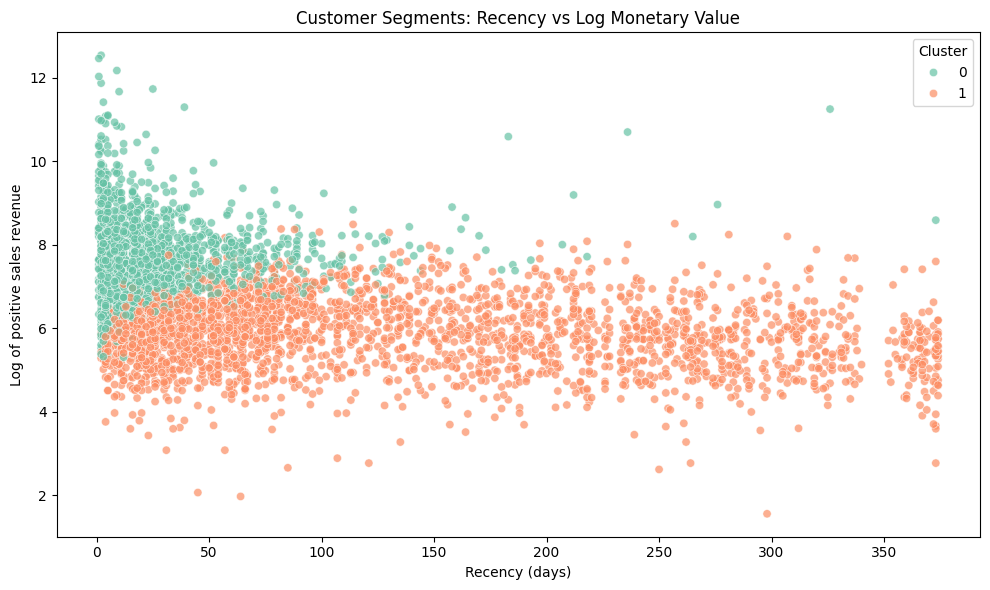

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = rfm_clustered.copy()

# Log scale makes the wide spending range easier to see
plot_df["Log_Monetary"] = np.log1p(plot_df["Monetary"])

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="Recency",
    y="Log_Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segments: Recency vs Log Monetary Value")
plt.xlabel("Recency (days)")
plt.ylabel("Log of positive sales revenue")
plt.tight_layout()
plt.show()

In [33]:
profile_2 = (
    rfm_clustered.groupby("Cluster")
    .agg(
        Customers=("Recency", "size"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Recency=("Recency", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary=("Monetary", "mean")
    )
    .round(2)
)

profile_2["Customer_Percentage"] = (
    profile_2["Customers"] / len(rfm_clustered) * 100
).round(2)

print(profile_2)

         Customers  Median_Recency  Median_Frequency  Median_Monetary  \
Cluster                                                                 
0             1668            17.0               6.0          2058.17   
1             2670            96.0               1.0           362.01   

         Mean_Recency  Mean_Frequency  Mean_Monetary  Customer_Percentage  
Cluster                                                                    
0               26.45            8.44        4535.74                38.45  
1              134.67            1.67         494.98                61.55  


In [34]:
# Add readable segment names to the K=3 dataset
segment_names = {
    0: "Frequent_Higher_Spending",
    1: "Less_Recent_Occasional",
    2: "Recent_Moderately_Active"
}

rfm_final = rfm_3.copy()
rfm_final["Segment"] = (
    rfm_final["Cluster"].map(segment_names)
)

# Save the customer-level segmentation
rfm_final.to_csv(
    "retail_customer_segments.csv",
    index=True
)

print(rfm_final.head())

print("\nSegment counts:")
print(rfm_final["Segment"].value_counts())

print("\nFile saved successfully.")

            Recency  Frequency  Monetary        LastPurchase  R_Score  \
CustomerID                                                              
12346           326          1  77183.60 2011-01-18 10:01:00        1   
12347             3          7   4310.00 2011-12-07 15:52:00        4   
12348            76          4   1797.24 2011-09-25 13:13:00        2   
12349            19          1   1757.55 2011-11-21 09:51:00        3   
12350           311          1    334.40 2011-02-02 16:01:00        1   

            F_Score  M_Score RFM_Score  Cluster                   Segment  
CustomerID                                                                 
12346             1        4       114        2  Recent_Moderately_Active  
12347             4        4       444        0  Frequent_Higher_Spending  
12348             3        4       234        2  Recent_Moderately_Active  
12349             1        4       314        2  Recent_Moderately_Active  
12350             1        2    

In [35]:
from google.colab import files

files.download("retail_customer_segments.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>